# Gold as an electrical conductor: a data-driven comparison
Gold is not the best electrical conductor, yet it is used in connectors, contacts and sensors. This notebook asks why, using open data for the elements.

**Steps in this notebook**
1. Rank metals by electrical conductivity.
2. Test the Wiedemann–Franz law (are electrons carrying both heat and charge?).
3. Compare conductivity with corrosion resistance (nobility).
4. Optional: cost per unit conductance, once you add dated prices to `data/prices.csv`.

**Data source:** element properties from the `pymatgen` periodic table (Ong et al., *Comput. Mater. Sci.* 68, 314, 2013). Values are near room temperature and rounded. Check key values against a primary source such as the CRC Handbook before publishing. Note that published values for gold's resistivity differ (about 22.1 nΩ·m in handbook-type tables, 24.4 nΩ·m in many textbook tables), and Section 3 shows how much this matters.

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os, warnings
from pymatgen.core import Element
from scipy.constants import k as kB, e as qe, pi
warnings.filterwarnings("ignore")
os.makedirs("data",exist_ok=True); os.makedirs("figures",exist_ok=True)
plt.rcParams.update({"figure.dpi":120,"axes.spines.top":False,"axes.spines.right":False})

## 1. Load the data

In [2]:
# Standard electrode potentials (V vs SHE) from the OpenStax/LibreTexts standard-potential table (Au3+/Au; Pt2+, Pd2+, Ag+, Cu2+, Ni2+, Fe2+, Al3+).
# Pb, Sn and Zn values are from memory and still need checking against a source.
E0={"Au":1.498,"Pt":1.20,"Pd":0.987,"Ag":0.7996,"Cu":0.34,"Pb":-0.126,"Sn":-0.14,"Ni":-0.257,"Fe":-0.447,"Zn":-0.762,"Al":-1.662}
rows=[]
for s in ["Ag","Cu","Au","Al","W","Zn","Ni","Pd","Pt","Fe","Sn","Pb","Ti"]:
    el=Element(s)
    rows.append(dict(symbol=s,resistivity_ohm_m=float(el.electrical_resistivity),
        thermal_cond_W_mK=float(el.thermal_conductivity),density_kg_m3=float(el.density_of_solid),
        E0_V=E0.get(s,np.nan)))
df=pd.DataFrame(rows)
df["conductivity_MS_m"]=1/df.resistivity_ohm_m/1e6
df["rel_to_copper_%"]=df.resistivity_ohm_m[df.symbol=="Cu"].iloc[0]/df.resistivity_ohm_m*100
df["resistivity_nOhm_m"]=df.resistivity_ohm_m*1e9
df.to_csv("data/metals.csv",index=False)
df.sort_values("resistivity_ohm_m")[["symbol","resistivity_nOhm_m","conductivity_MS_m","rel_to_copper_%","thermal_cond_W_mK","density_kg_m3","E0_V"]].round(2)

,symbol,resistivity_nOhm_m,conductivity_MS_m,rel_to_copper_%,thermal_cond_W_mK,density_kg_m3,E0_V
0,Ag,15.87,63.01,105.73,430.0,10490.0,0.80
1,Cu,16.78,59.59,100.00,400.0,8920.0,0.34
2,Au,22.14,45.17,75.79,320.0,19300.0,1.50
3,Al,26.50,37.74,63.32,235.0,2700.0,-1.66
4,W,52.80,18.94,31.78,170.0,19250.0,NaN
5,Zn,59.00,16.95,28.44,120.0,7140.0,-0.76
6,Ni,69.30,14.43,24.21,91.0,8908.0,-0.26
9,Fe,96.10,10.41,17.46,80.0,7874.0,-0.45
8,Pt,105.00,9.52,15.98,72.0,21090.0,1.20
7,Pd,105.40,9.49,15.92,72.0,12023.0,0.99


## 2. Conductivity ranking

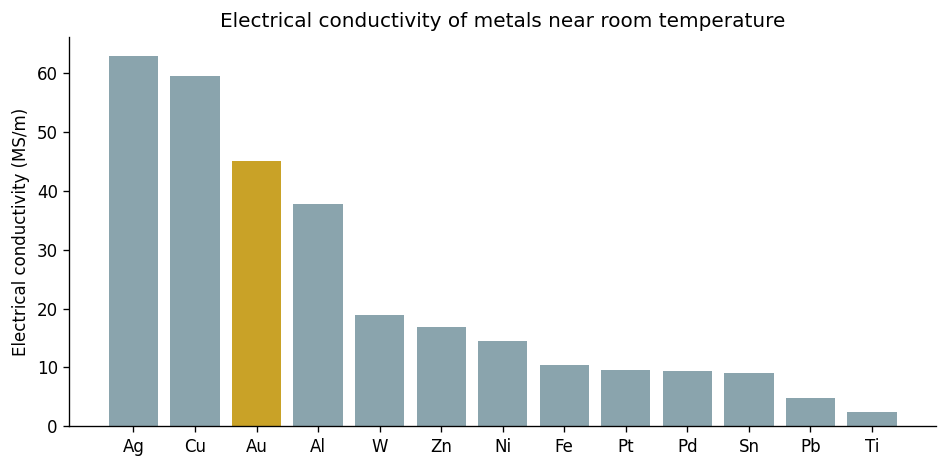

Gold: 45.2 MS/m, about 76% of copper's conductivity; rank 3 of 13.


In [3]:
d=df.sort_values("conductivity_MS_m",ascending=False)
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(d.symbol,d.conductivity_MS_m,color=["#c9a227" if s=="Au" else "#8aa4ad" for s in d.symbol])
ax.set_ylabel("Electrical conductivity (MS/m)");ax.set_title("Electrical conductivity of metals near room temperature")
fig.tight_layout();fig.savefig("figures/conductivity_ranking.png");plt.show()
au=df[df.symbol=="Au"].iloc[0]
print(f"Gold: {au.conductivity_MS_m:.1f} MS/m, about {au['rel_to_copper_%']:.0f}% of copper's conductivity; rank {list(d.symbol).index('Au')+1} of {len(d)}.")

## 3. Wiedemann–Franz law
For metals, thermal conductivity κ, electrical resistivity ρ and temperature T should satisfy κρ/T = L₀, where L₀ = (π²/3)(k_B/e)² ≈ 2.44×10⁻⁸ W·Ω/K². We assume T ≈ 293 K for the tabulated values; this is an assumption to check.

Sommerfeld value L0 = 2.443e-08


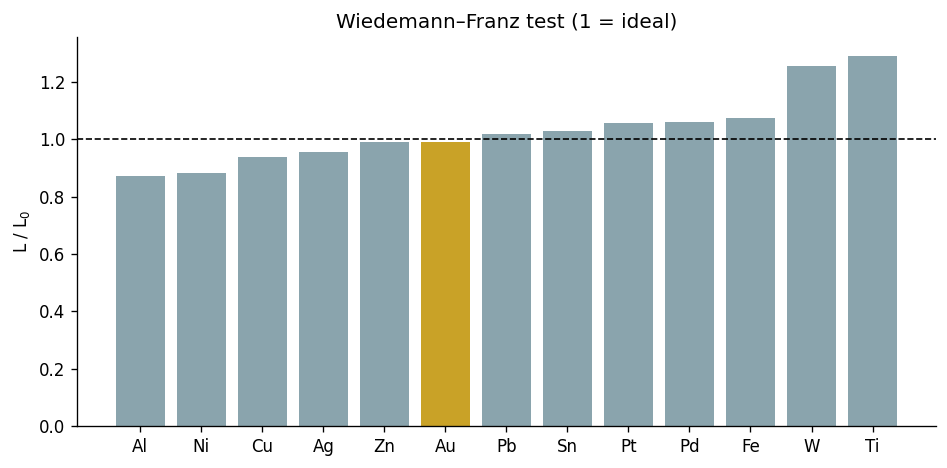

,symbol,Lorenz_1e8,L_over_L0
3,Al,2.125,0.870
6,Ni,2.152,0.881
1,Cu,2.291,0.938
0,Ag,2.329,0.953
5,Zn,2.416,0.989
2,Au,2.418,0.990
11,Pb,2.485,1.017
10,Sn,2.515,1.030
8,Pt,2.580,1.056
7,Pd,2.590,1.060


In [4]:
T=293.0; L0=(pi**2/3)*(kB/qe)**2
df["Lorenz_number"]=df.thermal_cond_W_mK*df.resistivity_ohm_m/T
df["L_over_L0"]=df.Lorenz_number/L0
print(f"Sommerfeld value L0 = {L0:.3e}")
w=df.sort_values("L_over_L0")
fig,ax=plt.subplots(figsize=(8,4))
ax.bar(w.symbol,w.L_over_L0,color=["#c9a227" if s=="Au" else "#8aa4ad" for s in w.symbol])
ax.axhline(1,color="k",lw=1,ls="--");ax.set_ylabel("L / L$_0$");ax.set_title("Wiedemann–Franz test (1 = ideal)")
fig.tight_layout();fig.savefig("figures/wiedemann_franz.png");plt.show()
w.assign(Lorenz_1e8=w.Lorenz_number*1e8)[["symbol","Lorenz_1e8","L_over_L0"]].round(3)

**Reading the result.** With the dataset value for gold (22.14 nΩ·m) gold sits within about 1% of the ideal value. With the 24.4 nΩ·m figure given in many textbook tables it sits about 9% above it (see the sensitivity table below), so the conclusion depends on which gold resistivity is used. Tungsten and titanium deviate by 25–30%. A likely reason is that heat carried by lattice vibrations (phonons) matters more in poorer conductors, but this should be checked against the literature before it is stated in a paper.

### Sensitivity to the value used for gold's resistivity

In [5]:

cu_rho=df.loc[df.symbol=="Cu","resistivity_ohm_m"].iloc[0]
k_au=df.loc[df.symbol=="Au","thermal_cond_W_mK"].iloc[0]
rows=[]
for label,rho in [("Dataset value (handbook-type)",22.14e-9),("Textbook-table value",24.4e-9)]:
    rows.append({"Source of gold resistivity":label,"rho (nOhm m)":rho*1e9,"sigma (MS/m)":round(1/rho/1e6,1),
                 "% of copper":round(cu_rho/rho*100),"L/L0":round(k_au*rho/T/L0,3)})
pd.DataFrame(rows)


,Source of gold resistivity,rho (nOhm m),sigma (MS/m),% of copper,L/L0
0,Dataset value (handbook-type),22.14,45.2,76,0.990
1,Textbook-table value,24.40,41.0,69,1.091


## 4. Conductivity versus corrosion resistance

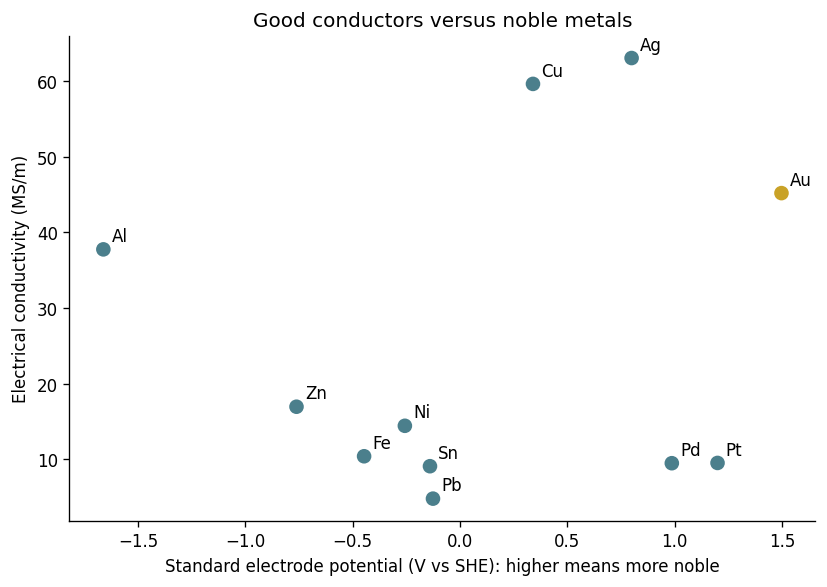

In [6]:
n=df.dropna(subset=["E0_V"])
fig,ax=plt.subplots(figsize=(7,5))
ax.scatter(n.E0_V,n.conductivity_MS_m,s=60,color=["#c9a227" if s=="Au" else "#4b7f8c" for s in n.symbol],zorder=3)
for _,r in n.iterrows(): ax.annotate(r.symbol,(r.E0_V,r.conductivity_MS_m),xytext=(5,5),textcoords="offset points")
ax.set_xlabel("Standard electrode potential (V vs SHE): higher means more noble")
ax.set_ylabel("Electrical conductivity (MS/m)");ax.set_title("Good conductors versus noble metals")
fig.tight_layout();fig.savefig("figures/conductivity_vs_nobility.png");plt.show()

**Reading the result.** Silver and copper conduct better than gold, but gold is far more noble, so it resists oxidation. In connectors an oxide film raises contact resistance over time, which is why gold is used even though it conducts less. Electrode potential is only a thermodynamic proxy. Real corrosion also depends on kinetics and the environment (silver, for example, tarnishes in sulfur-containing air).

## 5. Cost per unit conductance (optional)
For a wire of fixed length and resistance, mass is proportional to density × resistivity, so cost is proportional to price × density × resistivity. Fill `data/prices.csv` with a dated, cited price for each metal (USD/kg) and re-run this cell.

In [7]:
if not os.path.exists("data/prices.csv"):
    pd.DataFrame({"symbol":df.symbol,"usd_per_kg":"","price_date":"","source":""}).to_csv("data/prices.csv",index=False)
p=pd.read_csv("data/prices.csv").dropna(subset=["usd_per_kg"])
if len(p):
    m=df.merge(p,on="symbol"); m["cost_index"]=m.usd_per_kg*m.density_kg_m3*m.resistivity_ohm_m
    m["cost_vs_copper"]=m.cost_index/m.loc[m.symbol=="Cu","cost_index"].iloc[0]
    display(m[["symbol","usd_per_kg","price_date","cost_vs_copper"]].sort_values("cost_vs_copper"))
else:
    print("Add prices to data/prices.csv to enable this step.")

Add prices to data/prices.csv to enable this step.


## Limitations
- Values are rounded, and their reference temperatures are not all stated; confirm key values in a primary source.
- Electrode potential is not a corrosion rate.
- Bulk metals only. Thin films and nanowires of gold are more resistive because electrons scatter at surfaces and grain boundaries; modelling this is planned next.

## Planned
Size-effect model for gold thin films, and a short section on uses beyond currency and jewellery: connectors, flexible electronics, sensors, printed inks and electrodes.